# Machine Learning Homework - Group 22
## Notebook 3 - Feature Selection

**Objective**: Define a clear feature selection strategy using methods discussed in classes, present and justify the final feature set.

**Inputs**: `data/train_clean.csv`, `data/test_clean.csv`, `data/feature_lists.csv` and `artifacts/features/encoder_categories.csv` (from Notebook 2)

**Outputs**: `data/selected_features.csv`, `data/selected_columns.csv`, `artifacts/features/selection_stages.csv`, `artifacts/features/selection_scores.csv`, `artifacts/logs/selection_log.csv`, `artifacts/figures/nb03_selection_funnel.png`,
`artifacts/figures/nb03_final_feature_set.png`, `artifacts/figures/nb03_cv_by_feature_set.png`

### The 5 stages:

| Stage | Method | Why this stage exists |
|---|---|---|
| Near-constant filter |`VarianceThreshold`| A column that barely varies cannot separate classes. Notebook 2 left several such flags |
|Redundancy pruning | `pandas.corr` + the Notebook 1 rule \|r\| >= 0.8 | Notebook 1 identified 16 pairs of highly correlated features. Keeping both features in each pair would split their importance between them |
|Univariate association screen |`SelectKBest` with a custom score function |Measures each column association with the target, the score is the point-biserial correlation Notebook 1 used |
| Model-based ranking | `SelectFromModel(DecisionTreeClassifier)` and `RFE(LogisticRegression)`|A univariate association cannot see interactions (tree) or joint contribution (RFE), both rank, neither is trusted alone|
|Evidence-based choice | `cross_validate` under `StratifiedKFold` (criterion) and `GroupKFold` (stricter check) |The final set is chosen by measured cross-validated F1 and the ranking is shown under both protocols |

**No re-preprocessing:** Notebook 2 already imputed, log-transformed, scaled and encoded, fitted on training rows only.

**Nothing here touches `test` other than to carry its columns through:** Every selector is fitted on `train` rows only and the final set is written once for Notebook 4.

### Order of operations:
1. Environment
2. Load and verify
3. Build the candidate pool and the group map
4. Stage 1 - near-constant filter
5. Stage 2 - redundancy pruning
6. Stage 3 - univariate feature selection
7. Stage 4 - model-based rankings
8. Stage 5 - measured comparison
9. Final choice
10. Export feature selection results and log
11. Handover

### Cell 1 - Environment:
Setup libraries, theme, environment, feature selection log and variables used for feature selection.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.feature_selection import VarianceThreshold, SelectKBest, SelectFromModel, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_validate
from sklearn.metrics import get_scorer
pd.set_option('display.max_columns', None)

ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
ARTIFACTS_DIR = ROOT / "artifacts"
FIG_DIR = ARTIFACTS_DIR / "figures"
LOG_DIR = ARTIFACTS_DIR / "logs"
FEAT_DIR = ARTIFACTS_DIR / "features"

TARGET = "repeat_purchase_90d"
RANDOM_STATE = 42
PLOT_BLUE = "#1779A8"
PLOT_ORANGE = "#C96A00"

REDUNDENCY_CUTOFF = 0.80
UNIVARIATE_CUTOFF = 0.05
N_SPLITS = 5

SEL_LOG = []

def log_stage(stage, method, before, after, detail):
    SEL_LOG.append({"stage": stage, "method": method, "groups_before": before, "groups_after": after, "detail": detail})

def guide(ax, text):
    ax.set_title(ax.get_title() + "\n" + text, fontsize=9)

sns.set_theme(style="whitegrid")
print("Environment ready.")
print(" inputs :", DATA_DIR / "train_clean.csv")
print(f" outputs:\n  {FEAT_DIR},\n  {LOG_DIR},\n  {FIG_DIR}")

Environment ready.
 inputs : C:\Users\gusta\Desktop\homework ML\data\train_clean.csv
 outputs:
  C:\Users\gusta\Desktop\homework ML\artifacts\features,
  C:\Users\gusta\Desktop\homework ML\artifacts\logs,
  C:\Users\gusta\Desktop\homework ML\artifacts\figures


### Cell 2 - Load and verify:
Read created matrices from Notebook 2 and check if everything is ready for feature selection.

We load the cleaned `train` and `test` datasets, along with the feature lists and encoding information produced in Notebook 2. We then check the dataset dimensions, target distribution, number of features available for modelling and number of missing values.

In [2]:
train = pd.read_csv(DATA_DIR / "train_clean.csv")
test = pd.read_csv(DATA_DIR / "test_clean.csv")
lists = pd.read_csv(DATA_DIR / "feature_lists.csv")
enc_cats = pd.read_csv(FEAT_DIR / "encoder_categories.csv")

ID_COLS = ["ID", "customer_id"]
y = train[TARGET]

print("Shapes:")
print("  train:", train.shape, "| test:", test.shape)
print("  target positive rate:", round(float(y.mean()), 4))

modelled = lists[lists["kind"].isin(["numeric_scaled", "indicator_flag", "one_hot"])]
print("\nCandidate pool declared by Notebook 2:")
print(modelled["kind"].value_counts().to_string())
print(" total modelled features:", len(modelled))
print(" excluded by Notebook 02:", lists[lists["kind"].str.startswith("excluded")]["feature"].tolist())

available = [c for c in train.columns if c not in ID_COLS + [TARGET]]
print("\nConsistency check:")
print(" columns in train_clean matching the declared pool:", len([c for c in available if c in set(modelled["feature"])]),
      "of", len(available))
assert set(available) == set(modelled["feature"]), "Notebook 2 and its feature list disagree"
assert train[available].isna().sum().sum() == 0 and test[available].isna().sum().sum() == 0
assert sorted(train[available].columns) == sorted(test[available].columns)
print(" no nulls, train/test columns aligned")

Shapes:
  train: (6469, 128) | test: (986, 127)
  target positive rate: 0.5597

Candidate pool declared by Notebook 2:
kind
one_hot           82
numeric_scaled    30
indicator_flag    13
 total modelled features: 125
 excluded by Notebook 02: ['purchase_year', 'random_noise', 'municipality', 'city', 'postal_area', 'postal_code', 'street', 'address', 'customer_type', 'company_name']

Consistency check:
 columns in train_clean matching the declared pool: 125 of 125
 no nulls, train/test columns aligned


### Cell 3 - Group map:
Group the one-hot encoded columns by their original categorical feature, so that all dummy variables from the same feature are considered together.

Numeric and flags features are kept as individual groups. We then examine the number and composition of these groups, verify that every available feature is included and define a helper function `group_columns` to retrieve the corresponding features for any selected set of groups.

In [3]:
enc_columns = enc_cats["column"].tolist()

group_of = {}
for col in available:
    if col.startswith("cat_"):
        source = None
        for c in enc_columns:
            if col.startswith("cat_" + c + "_"):
                source = c
                break
        group_of[col] = source if source is not None else col
    else:
        group_of[col] = col

feature_group = pd.Series(group_of)
groups = sorted(set(feature_group.values))
group_members = {g: [c for c in available if feature_group[c] == g] for g in groups}

comp = pd.DataFrame({"group": groups, "n_columns": [len(group_members[g]) for g in groups],
                     "kind": ["one_hot" if g in enc_columns else
                              ("flag" if str(g).startswith("flag_") else "numeric") for g in groups]})
print("Groups that selection will decide on:")
print(" groups:", len(groups), "| columns:", len(available))
print(" composition:")
print(comp["kind"].value_counts().to_string())
print("\n  multi-column groups (one-hot concepts):")
for g in comp[comp["n_columns"] > 1]["group"]:
    print(f"    {g:24s} {len(group_members[g]):3d} dummies")
print("\n  single-column groups:", int((comp["n_columns"] == 1).sum()))
assert sum(len(v) for v in group_members.values()) == len(available)


def group_columns(gs, universe):
    return [c for g in gs for c in group_members[g] if c in universe]

Groups that selection will decide on:
 groups: 54 | columns: 125
 composition:
kind
numeric    30
flag       13
one_hot    11

  multi-column groups (one-hot concepts):
    commercial_region         11 dummies
    commercial_zone            2 dummies
    country_or_region          2 dummies
    customer_since_year        9 dummies
    document_series            2 dummies
    island                    10 dummies
    payment_type               5 dummies
    purchase_month            11 dummies
    salesperson                6 dummies
    transport_method          22 dummies
    warehouse                  2 dummies

  single-column groups: 43


### Cell 4 - Stage 1, near-constant filter:
Remove columns that carry almost no variation.

We apply `VarianceThreshold` with a threshold of 0.01 to identify and remove features with very low variability. Features that are almost constant across observations are unlikely to help predict if customers will repeat purchase or not. The filter is fitted only on `train` dataset, `vt.fit(train[available])`. To be consistent with the previous step, removing any column also removes its entire feature group.

In [4]:
vt = VarianceThreshold(threshold=0.01)
vt.fit(train[available])
kept_cols = [c for c, k in zip(available, vt.get_support()) if k]
dropped_cols = [c for c, k in zip(available, vt.get_support()) if not k]

var_now = train[available].var()
dropped_groups = sorted({feature_group[c] for c in dropped_cols})
kept_groups = [g for g in groups if g not in dropped_groups]

print("=== Stage 1: VarianceThreshold (threshold=0.01) ===")
print(" columns kept:", len(kept_cols), "of", len(available))
print(" groups kept :", len(kept_groups), "of", len(groups))
print("\n  dropped columns and their variance (train):")
for c in dropped_cols:
    print(f"    {c:46s} var = {float(var_now[c]):.5f}")
if not dropped_cols:
    print("    none - every column carries some variation")
assert len(kept_groups) == len(groups) - len(dropped_groups)
log_stage("1 variance", "VarianceThreshold(0.01)", len(groups), len(kept_groups),
          "{} groups dropped: {}".format(len(dropped_groups), ", ".join(dropped_groups) if dropped_groups else "none"))

=== Stage 1: VarianceThreshold (threshold=0.01) ===
 columns kept: 113 of 125
 groups kept : 42 of 54

  dropped columns and their variance (train):
    flag_sentinel_prior_mean_purchase_value        var = 0.00247
    flag_sentinel_spend_365d                       var = 0.00231
    flag_negative_prior_mean_purchase_value        var = 0.00247
    flag_negative_spend_365d                       var = 0.00231
    flag_negative_days_since_previous_purchase     var = 0.00247
    flag_negative_prior_mean_gap_days              var = 0.00247
    cat_salesperson_Other                          var = 0.00797
    cat_commercial_zone_Other                      var = 0.00889
    cat_warehouse_Other                            var = 0.00324
    cat_country_or_region_Other                    var = 0.00293
    cat_island_Other                               var = 0.00154
    cat_customer_since_year_Other                  var = 0.00400


The variance filter removed **12 out of 125 columns**, reducing the feature set from **54 to 42 groups**. The excluded features consist of 6 indicator flags and 6 one-hot encoded "Other" categories, all with low variances (<0.01). The remaining 113 columns are retained for the next stage of feature selection, where redundancy between features will be examined.

### Cell 5 - Stage 2, redundancy pruning:
Identify potential redundancy between features groups and for each group pair remove the group with weaker association with the target.

Each group has a representative feature, the one strongest absolute correlation with the target. We then calculate the pairwise Pearson correlations between these representatives and identify pairs whose absolute correlation exceeds the defined threshold.

In [5]:
pool_cols = [c for c in kept_cols]
X_pool = train[pool_cols]
assoc_pool = pd.Series({c: abs(float(np.corrcoef(X_pool[c], y)[0, 1])) for c in pool_cols})

group_rep = {g: max([c for c in group_members[g] if c in kept_cols], key=lambda c: assoc_pool.get(c, 0.0))
             for g in kept_groups}
rep_names = [group_rep[g] for g in kept_groups]
rep_corr = X_pool[rep_names].corr(numeric_only=True)

pairs = []
for i, ga in enumerate(kept_groups):
    for gb in kept_groups[i + 1:]:
        v = rep_corr.loc[group_rep[ga], group_rep[gb]]
        if pd.notna(v) and abs(v) >= REDUNDENCY_CUTOFF:
            pairs.append({"group_a": ga, "group_b": gb, "r": v,
                          "assoc_a": assoc_pool[group_rep[ga]], "assoc_b": assoc_pool[group_rep[gb]]})
pairs_df = pd.DataFrame(pairs, columns=["group_a", "group_b", "r", "assoc_a", "assoc_b"])
if len(pairs_df):
    pairs_df = pairs_df.sort_values("r", key=abs, ascending=False)

print(f"=== Stage 2: drop the weaker member of each |r| >= {REDUNDENCY_CUTOFF:.2f} group pair ===")
if len(pairs_df):
    display(pairs_df.round(3).style.hide(axis="index"))
else:
    print("No redundant pairs")

dropped_redun = []
for _, row in pairs_df.iterrows():
    if row["group_a"] in dropped_redun or row["group_b"] in dropped_redun:
        continue
    loser = row["group_b"] if row["assoc_a"] >= row["assoc_b"] else row["group_a"]
    dropped_redun.append(loser)

kept_groups_2 = [g for g in kept_groups if g not in dropped_redun]
kept_cols_2 = group_columns(kept_groups_2, kept_cols)
print("\n groups dropped for redundancy:", dropped_redun if dropped_redun else "none")
print(f" groups kept: {len(kept_groups_2)} | columns kept: {len(kept_cols_2)}")
log_stage("2 redundancy", "pandas.corr on group representatives, |r| >= {:.2f}".format(REDUNDENCY_CUTOFF), len(kept_groups), len(kept_groups_2),
          "{} pairs, dropped {}".format(len(pairs_df), dropped_redun if dropped_redun else "none"))

=== Stage 2: drop the weaker member of each |r| >= 0.80 group pair ===


group_a,group_b,r,assoc_a,assoc_b
Total Liquido,Total a Pagar,1.000000,0.036000,0.039000
Total Bruto,Total Liquido,0.992000,0.063000,0.036000
Total Bruto,Total a Pagar,0.991000,0.063000,0.039000
prior_max_purchase_value,prior_total_spend,0.964000,0.230000,0.275000
prior_mean_gap_days,prior_std_gap_days,0.950000,0.003000,0.033000
mean_ticket_365d,spend_365d,0.946000,0.184000,0.302000
prior_max_purchase_value,prior_mean_purchase_value,0.945000,0.230000,0.160000
purchase_count_180d,purchase_count_365d,0.917000,0.407000,0.424000
recent_share_30_90d,spend_30d,0.915000,0.168000,0.234000
flag_no_purchase_history,prior_max_purchase_value,-0.902000,0.146000,0.230000



 groups dropped for redundancy: ['Total Liquido', 'Total a Pagar', 'prior_max_purchase_value', 'prior_mean_gap_days', 'mean_ticket_365d', 'purchase_count_180d', 'recent_share_30_90d', 'prior_mean_purchase_value', 'spend_30d', 'prior_total_spend', 'spend_90d', 'prior_purchase_count', 'spend_365d', 'purchase_count_30d']
 groups kept: 28 | columns kept: 74


The redundancy analysis identified **28 highly correlated pairs** (|r| >= 0.8), mainly involving purchase amounts, history spends and purchase frequency. Some features contained redudant information, such as `Total Liquido` and `Total a Pagar` (r ≈ 1.00), and `purchase_count_180d` and `purchase_count_365d` (r = 0.917). By removing the feature groups with weaker correlation with the target, we reduced the dataset from **42 to 28 groups**, retaining **74 columns**. The final utility of these features is not yet guaranteed, during the subsequent selection phases.

### Cell 6 - Stage 3, univariate feature selection:
Assess the individual correlation between each remaining feature and the target using the absolute point-biserial correlation. Using `SelectKBest` with a custom scoring function, a score is calculated for every column and assign each feature group its highest score. Groups whose scores are below the defined threshold are dropped.

In [6]:
def abs_pbiserial(X, y):
    X = np.asarray(X, dtype=float)
    yv = np.asarray(y, dtype=float)
    scores = np.zeros(X.shape[1])
    for j in range(X.shape[1]):
        col = X[:, j]
        if col.std() == 0 or yv.std() == 0:
            scores[j] = 0.0
        else:
            scores[j] = abs(float(np.corrcoef(col, yv)[0, 1]))
    pvals = np.ones(X.shape[1])
    return scores, pvals


X_stage2 = train[kept_cols_2]
sk = SelectKBest(score_func=abs_pbiserial, k="all")
sk.fit(X_stage2, y)
col_scores = pd.Series(sk.scores_, index=kept_cols_2)

group_score = pd.Series({g: float(max(col_scores[c] for c in group_members[g] if c in kept_cols_2)) for g in kept_groups_2})
group_score = group_score.sort_values(ascending=False)
kept_groups_3 = [g for g in group_score.index if group_score[g] >= UNIVARIATE_CUTOFF]
kept_cols_3 = group_columns(kept_groups_3, kept_cols)

print(f"=== Stage 3: keep groups whose best |point-biserial r| >= {UNIVARIATE_CUTOFF:.2f} ===")
report = pd.DataFrame({"group": group_score.index, "abs_r": group_score.values, "n_columns": [len(group_members[g]) for g in group_score.index],
                       "kept": [g in kept_groups_3 for g in group_score.index]})
display(report.set_index("group"))
print("\n  groups kept: {} of {} | columns kept: {}".format(len(kept_groups_3), len(kept_groups_2), len(kept_cols_3)))
log_stage("3 univariate", "SelectKBest(custom point-biserial), cutoff {:.2f}".format(UNIVARIATE_CUTOFF),
          len(kept_groups_2), len(kept_groups_3),
          "{} groups below cutoff".format(len(kept_groups_2) - len(kept_groups_3)))

=== Stage 3: keep groups whose best |point-biserial r| >= 0.05 ===


,abs_r,n_columns,kept
group,,,
purchase_count_365d,0.423960,1,True
purchase_count_90d,0.396402,1,True
spend_180d,0.317004,1,True
payment_type,0.228137,5,True
prior_std_purchase_value,0.226684,1,True
Total Desc_ Linha,0.193076,1,True
commercial_region,0.165602,11,True
flag_no_purchase_history,0.146232,1,True
customer_tenure_days,0.106338,1,True



  groups kept: 18 of 28 | columns kept: 63


The feature selection stage above reduced the feature set from **28 to 18 groups**, keeping **63 features**. Using a minimum absolute point-biserial correlation of 0.05, we removed the 10 groups with weakeast associations with the target. Purchase frequency features showed the highest correlations: `purchase_count_365d` (r=0.424), `purchase_count_90d` (r=0.396) and `spend_180d` (r=0.317). This suggests that historical purchasing behaviour is very relevant for the model. Features with low individual correlations may still contribute when combined with others, so the remaining groups will be further assessed using model-based selection methods.

### Cell 7 - Stage 4, model-based rankings:
Ask two models what a univariate feature selection cannot see.

Firstly, `SelectFromModel` with a Decision Tree selects features whose importance exceeds the mean importance. Next, `RFE` with Logistic Regression removes the least important features until 20 remain. We then map the selected columns back to their original feature groups and compare the results of both methods, looking at which groups were selected by both, by only one and by neither.

In [7]:
X3 = train[kept_cols_3]

tree_sel = SelectFromModel(DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE))
tree_sel.fit(X3, y)
tree_imp = pd.Series(tree_sel.get_support(), index=kept_cols_3).astype(int)
tree_scores = pd.Series(tree_sel.estimator_.feature_importances_, index=kept_cols_3)

rfe = RFE(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), n_features_to_select=20, step=5)
rfe.fit(X3, y)
rfe_rank = pd.Series(rfe.ranking_, index=kept_cols_3)

tree_groups = sorted({feature_group[c] for c in kept_cols_3 if tree_imp[c] == 1})
rfe_groups = sorted({feature_group[c] for c in kept_cols_3 if rfe_rank[c] <= 20})

print("=== Stage 4a: SelectFromModel(DecisionTreeClassifier) ===")
print(" columns above the mean-importance threshold:", int(tree_imp.sum()), "of", len(kept_cols_3))
print(" groups selected:", len(tree_groups))
print("\n=== Stage 4b: RFE(LogisticRegression, 20 features) ===")
print(" groups selected:", len(rfe_groups))
print("\n  agreement with the Stage 3 survivors:")
print("   in both tree and RFE :", sorted(set(tree_groups) & set(rfe_groups)))
print("   tree only            :", sorted(set(tree_groups) - set(rfe_groups)))
print("   RFE only             :", sorted(set(rfe_groups) - set(tree_groups)))
print("   neither              :", sorted(set(kept_groups_3) - set(tree_groups) - set(rfe_groups)))
log_stage("4 model-based", "SelectFromModel(tree) + RFE(logistic)", len(kept_groups_3),
          len(set(tree_groups) | set(rfe_groups)),
          "tree {} groups, RFE {} groups".format(len(tree_groups), len(rfe_groups)))

=== Stage 4a: SelectFromModel(DecisionTreeClassifier) ===
 columns above the mean-importance threshold: 7 of 63
 groups selected: 7

=== Stage 4b: RFE(LogisticRegression, 20 features) ===
 groups selected: 18

  agreement with the Stage 3 survivors:
   in both tree and RFE : ['Total Bruto', 'Total Desc_ Linha', 'commercial_region', 'customer_tenure_days', 'prior_std_purchase_value', 'purchase_count_365d', 'spend_180d']
   tree only            : []
   RFE only             : ['Total Imp_', 'days_since_previous_purchase', 'flag_imputed_prior_std_gap_days', 'flag_no_purchase_history', 'flag_single_purchase', 'invoice_count_current_purchase', 'payment_type', 'prior_min_purchase_value', 'purchase_count_90d', 'purchase_month', 'transport_method']
   neither              : []


`SelectFromModel` selected **7 out of 63 columns**, corresponding to 7 feature groups, while `RFE` selected 20 columns covering all **18 remaining groups**. Both methods agreed on 7 groups, including `purchase_count_365d`, `spend_180d` and `customer_tenure_days`, showing that they have relevance for predicting repeat purchases. The remaining 11 groups were selected only by `RFE`. Since neither method gives us a final selection, the candidate feature sets will be compared using cross-validation in the next stage.

### Cell 8 - Stage 5, measured comparison:
Compare candidate feature sets by cross-validated F1 score.

The candidate sets are defined first, with drop of any duplicates. Using Logistic Regression as a reference model and F1 score as the evaluation metric, we assess each set through `StratifiedKFold`. We also apply `GroupKFold` using `customer_id` to evaluate performance when customers are kept separate across folds.

In [8]:
candidate_sets = {"A: all features": groups, "B: after variance": kept_groups, "C: + redundancy": kept_groups_2,
                  "D: + univariate": kept_groups_3, "E: tree selected": tree_groups, "F: RFE selected": rfe_groups,
                  "G: tree or RFE": sorted(set(tree_groups) | set(rfe_groups)), "H: tree and RFE": sorted(set(tree_groups) & set(rfe_groups))}

seen, unique_sets, duplicates = {}, {}, []
for name, gs in candidate_sets.items():
    key = frozenset(gs)
    if key in seen:
        duplicates.append(f"{name} == {seen[key]}")
        continue
    seen[key] = name
    unique_sets[name] = gs
print(f"=== Candidate sets compared ({len(unique_sets)} unique of {len(candidate_sets)} proposed) ===")
for d in duplicates:
    print("  duplicate dropped:", d)

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
cv_strict = GroupKFold(n_splits=N_SPLITS)
customer_ids = train["customer_id"].to_numpy()
ref_model = Pipeline([("clf", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))])
scorer = get_scorer("f1")

rows, fold_rows = [], []
for name, gs in unique_sets.items():
    cols = group_columns(gs, kept_cols)
    Xs = train[cols]
    scores = cross_validate(ref_model, Xs, y, cv=cv, scoring=scorer, return_train_score=True)
    strict = cross_validate(ref_model, Xs, y, cv=cv_strict, scoring=scorer, groups=customer_ids)
    rows.append({"feature_set": name, "n_groups": len(gs), "n_columns": len(cols),
                 "cv_f1_mean": scores["test_score"].mean(), "cv_f1_std": scores["test_score"].std(),
                 "cv_f1_grouped": strict["test_score"].mean(),
                 "cv_f1_grouped_std": strict["test_score"].std(),
                 "train_f1_mean": scores["train_score"].mean()})
    for k, s in enumerate(scores["test_score"], start=1):
        fold_rows.append({"feature_set": name, "fold": k, "f1": s})

results = pd.DataFrame(rows).sort_values("cv_f1_mean", ascending=False)
print("=== Stage 5: reference logistic model, scorer = F1, criterion = StratifiedKFold ===")
print(results.to_string(index=False, float_format=lambda v: "{:.4f}".format(v)))
best = results.head(1).to_dict("records")[0]
print(f"\n  best mean CV F1: {best["cv_f1_mean"]:.4f} ({best["feature_set"]})")
print(f"  spread across sets: {results["cv_f1_mean"].max() - results["cv_f1_mean"].min():.4f}")
same = results.sort_values("cv_f1_mean", ascending=False)["feature_set"].tolist()
same_g = results.sort_values("cv_f1_grouped", ascending=False)["feature_set"].tolist()
print("  ranking under StratifiedKFold : {}".format(", ".join(same)))
print("  ranking under GroupKFold      : {}".format(", ".join(same_g)))
if same[0] == same_g[0]:
    print("  the two protocols agree on the same winner.")
else:
    print("  they disagree: the stricter protocol would prefer '{}'. Both columns stay in the table,".format(same_g[0]))
    print("  and the parsimony rule below is applied to the stratified column, so the disagreement")
    print("  is reported rather than resolved by picking the friendlier protocol.")

=== Candidate sets compared (5 unique of 8 proposed) ===
  duplicate dropped: F: RFE selected == D: + univariate
  duplicate dropped: G: tree or RFE == D: + univariate
  duplicate dropped: H: tree and RFE == E: tree selected
=== Stage 5: reference logistic model, scorer = F1, criterion = StratifiedKFold ===
      feature_set  n_groups  n_columns  cv_f1_mean  cv_f1_std  cv_f1_grouped  cv_f1_grouped_std  train_f1_mean
  A: all features        54        113      0.7459     0.0058         0.7451             0.0132         0.7632
  D: + univariate        18         63      0.7456     0.0032         0.7404             0.0161         0.7519
B: after variance        42         88      0.7455     0.0088         0.7439             0.0160         0.7567
  C: + redundancy        28         74      0.7439     0.0051         0.7458             0.0160         0.7555
 E: tree selected         7         17      0.7317     0.0044         0.7304             0.0179         0.7355

  best mean CV F1: 0.745

The cross-validation results show that feature selection canreduce the number of predictor features without affecting predictive performance. Of the 8 proposed feature sets only 5 were unique. The full feature set achieved the mean F1 score under `StratifiedKFold` (F1=0.7459), which uses 54 groups and 113 columns in the full set, close to univariate selection set (F1=0.7456), which only uses 18 groups and 63 columns and after variance selection (F1=0.7455), which uses 42 groups and 88 columns. The Decision Tree selection performed worse (F1=0.7317), suggesting that reducing the feature set too aggressively may discard useful information. Under `GroupKFold` the redundancy-filtered set achieved the F1=0.7458. This confirms a simpler feature set can maintain predictive performance. We will choose the final feature set by considering every set performances and the number of features each one uses.

### Cell 9 - Final choice:
Select the final feature set based on the cross-validation results, considering all sets whose mean F1 score is within the average standard deviation of the best result and taking into account the number of features.

=== Final selection ===
 parsimony tolerance (mean fold std): 0.0054
 sets within tolerance of the best  : ['A: all features', 'D: + univariate', 'B: after variance', 'C: + redundancy']
 chosen set                           : D: + univariate
 groups: 18 | columns: 63 (from 125 candidates)
  mean CV F1 0.7456 (+/- 0.0032) vs full-feature set 0.7459

  composition of the final set:
kind
numeric    11
one_hot     4
flag        3

  selected groups:
    purchase_count_365d          |r| =  0.4240   1 column(s)
    purchase_count_90d           |r| =  0.3964   1 column(s)
    spend_180d                   |r| =  0.3170   1 column(s)
    payment_type                 |r| =  0.2281   5 column(s)
    prior_std_purchase_value     |r| =  0.2267   1 column(s)
    Total Desc_ Linha            |r| =  0.1931   1 column(s)
    commercial_region            |r| =  0.1656   11 column(s)
    flag_no_purchase_history     |r| =  0.1462   1 column(s)
    customer_tenure_days         |r| =  0.1063   1 column(s)


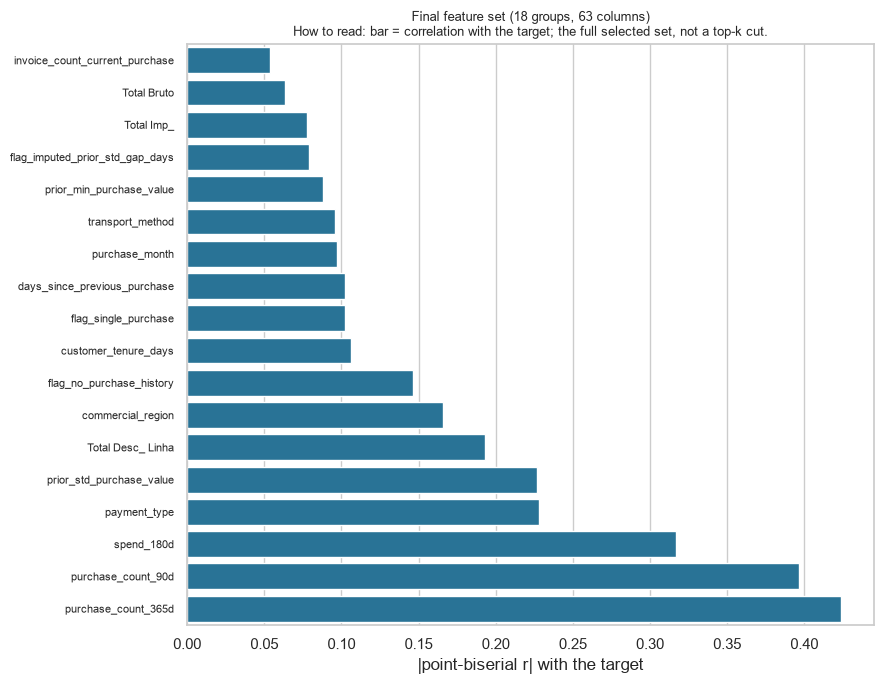

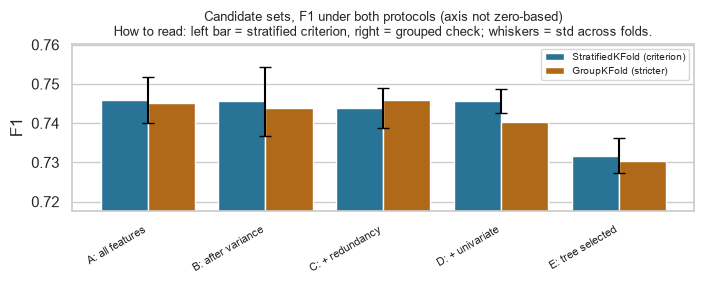

In [9]:
tol = results["cv_f1_std"].mean()
competitive = results[results["cv_f1_mean"] >= results["cv_f1_mean"].max() - tol]
final_row = competitive.sort_values(["n_groups", "cv_f1_mean"], ascending=[True, False]).head(1).to_dict("records")[0]
final_groups = candidate_sets[final_row["feature_set"]]
final_cols = group_columns(final_groups, kept_cols)

print("=== Final selection ===")
print(f" parsimony tolerance (mean fold std): {tol:.4f}")
print(" sets within tolerance of the best  :", competitive["feature_set"].tolist())
print(" chosen set                           :", final_row["feature_set"])
print(" groups: {} | columns: {} (from {} candidates)".format(
    final_row["n_groups"], final_row["n_columns"], len(available)))
print("  mean CV F1 {:.4f} (+/- {:.4f}) vs full-feature set {:.4f}".format(
    final_row["cv_f1_mean"], final_row["cv_f1_std"],
    float(results[results["feature_set"] == "A: all features"]["cv_f1_mean"].tolist()[0])))

final_group_cols = {g: [c for c in group_members[g] if c in kept_cols] for g in final_groups}
comp_final = pd.DataFrame({"group": final_groups,
                           "kind": ["one_hot" if g in enc_columns else
                                    ("flag" if str(g).startswith("flag_") else "numeric") for g in final_groups],
                           "n_columns": [len(final_group_cols[g]) for g in final_groups]})
print("\n  composition of the final set:")
print(comp_final["kind"].value_counts().to_string())
print("\n  selected groups:")
for g in sorted(final_groups, key=lambda x: -float(group_score.get(x, 0))):
    print("    {:28s} |r| = {:>7}   {} column(s)".format(
        g, "{:.4f}".format(float(group_score.get(g, float("nan")))), len(final_group_cols[g])))

fig, ax = plt.subplots(figsize=(9, 1.6 + 0.30 * len(final_groups)))
sel_scores = pd.DataFrame({"group": [g for g in final_groups],
                           "abs_r": [float(group_score.get(g, 0.0)) for g in final_groups]}
                          ).sort_values("abs_r")
sns.barplot(data=sel_scores, y="group", x="abs_r", orient="h", color=PLOT_BLUE, ax=ax)
ax.set_title("Final feature set ({} groups, {} columns)".format(len(final_groups), len(final_cols)))
ax.set_xlabel("|point-biserial r| with the target")
ax.set_ylabel("")
plt.setp(ax.get_yticklabels(), fontsize=8)
guide(ax, "How to read: bar = correlation with the target; the full selected set, not a top-k cut.")
plt.tight_layout()
plt.savefig(FIG_DIR / "nb03_final_feature_set.png", dpi=200)
plt.show()
fig, ax = plt.subplots(figsize=(7.2, 3.0))
order = list(unique_sets)
plot_df = results.set_index("feature_set").loc[order].reset_index()
long_df = pd.concat([
    plot_df[["feature_set", "cv_f1_mean", "cv_f1_std"]].rename(
        columns={"cv_f1_mean": "f1", "cv_f1_std": "std"}).assign(protocol="StratifiedKFold (criterion)"),
    plot_df[["feature_set", "cv_f1_grouped", "cv_f1_grouped_std"]].rename(
        columns={"cv_f1_grouped": "f1", "cv_f1_grouped_std": "std"}).assign(protocol="GroupKFold (stricter)"),
], ignore_index=True)
sns.barplot(data=long_df, x="feature_set", y="f1", hue="protocol",
              palette=[PLOT_BLUE, PLOT_ORANGE], ax=ax)
strat = long_df[long_df["protocol"].str.startswith("Stratified")]
plt.errorbar(x=[order.index(f) for f in strat["feature_set"]], y=strat["f1"], yerr=strat["std"],
             color="black", marker="none", linestyle="none", capsize=4)
axis_pad = max(float(plot_df["cv_f1_mean"].max() - plot_df["cv_f1_mean"].min()),
               float(plot_df["cv_f1_std"].mean()))
ax.set_ylim(float(plot_df["cv_f1_mean"].min()) - axis_pad, float(plot_df["cv_f1_mean"].max()) + axis_pad)
ax.set_title("Candidate sets, F1 under both protocols (axis not zero-based)")
ax.set_xlabel("")
ax.set_ylabel("F1")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right", fontsize=8)
ax.legend(loc="upper right", fontsize=7)
guide(ax, "How to read: left bar = stratified criterion, right = grouped check;"
      " whiskers = std across folds.")
plt.tight_layout()
plt.savefig(FIG_DIR / "nb03_cv_by_feature_set.png", dpi=200)
plt.show()

The final choice was **D: Univariate Selection**, with **18 groups and 63 columns**. This set achieved a mean cross-validated F1 score of **0.7456**, very close to the highest score of 0.7459, while using considerably fewer features. The selected features are in most part historical purchasing features, particularly purchase frequency and spending patterns.

### Cell 10 - Export feature selection results and log:
Save the selected features for use in the modelling stage and the decisions log and results of each selection method (number of groups and columns retained, F1 scores, and cross-validation performance).

We also create a bar chart showing how the number of features changes across the different stages.

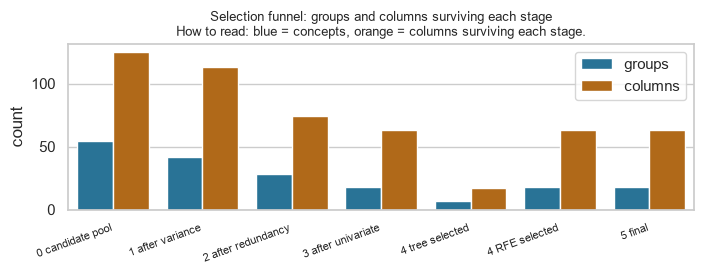

=== Selection funnel ===
             stage  groups  columns
  0 candidate pool      54      125
  1 after variance      42      113
2 after redundancy      28       74
3 after univariate      18       63
   4 tree selected       7       17
    4 RFE selected      18       63
           5 final      18       63

=== Log ===
        stage                                            method  groups_before  groups_after
   1 variance                           VarianceThreshold(0.01)             54            42
 2 redundancy pandas.corr on group representatives, |r| >= 0.80             42            28
 3 univariate   SelectKBest(custom point-biserial), cutoff 0.05             28            18
4 model-based             SelectFromModel(tree) + RFE(logistic)             18            18

Saved: data/selected_features.csv, artifacts/features/selection_stages.csv,
       selection_scores.csv, selection_cv_results.csv, artifacts/logs/selection_log.csv


In [10]:
pd.DataFrame({"group": final_groups, "columns": [", ".join(final_group_cols[g]) for g in final_groups],
              "n_columns": [len(final_group_cols[g]) for g in final_groups], "abs_r": [float(group_score.get(g, 0.0)) for g in final_groups]}
            ).to_csv(DATA_DIR / "selected_features.csv", index=False)

pd.DataFrame([{"group": g, "column": c, "abs_r": float(group_score.get(g, 0.0))}
              for g in final_groups for c in final_group_cols[g]]
             ).to_csv(DATA_DIR / "selected_columns.csv", index=False)

stages = pd.DataFrame([
    {"stage": "0 candidate pool", "groups": len(groups), "columns": len(available)},
    {"stage": "1 after variance", "groups": len(kept_groups), "columns": len(kept_cols)},
    {"stage": "2 after redundancy", "groups": len(kept_groups_2), "columns": len(kept_cols_2)},
    {"stage": "3 after univariate", "groups": len(kept_groups_3), "columns": len(kept_cols_3)},
    {"stage": "4 tree selected", "groups": len(tree_groups),
     "columns": len(group_columns(tree_groups, kept_cols))},
    {"stage": "4 RFE selected", "groups": len(rfe_groups),
     "columns": len(group_columns(rfe_groups, kept_cols))},
    {"stage": "5 final", "groups": len(final_groups), "columns": len(final_cols)},
])
stages.to_csv(FEAT_DIR / "selection_stages.csv", index=False)

funnel_long = pd.concat([
    stages[["stage", "groups"]].rename(columns={"groups": "count"}).assign(metric="groups"),
    stages[["stage", "columns"]].rename(columns={"columns": "count"}).assign(metric="columns"),
], ignore_index=True)
fig, ax = plt.subplots(figsize=(7.2, 2.9))   # print width: the PDF places this 1:1
sns.barplot(data=funnel_long, x="stage", y="count", hue="metric", orient="v",
            palette=[PLOT_BLUE, PLOT_ORANGE], ax=ax)
ax.set_title("Selection funnel: groups and columns surviving each stage")
ax.set_xlabel("")
ax.set_ylabel("count")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right", fontsize=8)
ax.legend()
guide(ax, "How to read: blue = concepts, orange = columns surviving each stage.")
plt.tight_layout()
plt.savefig(FIG_DIR / "nb03_selection_funnel.png", dpi=200)
plt.show()
pd.DataFrame({"column": col_scores.index, "abs_pointbiserial_r": col_scores.values}
             ).to_csv(FEAT_DIR / "selection_scores.csv", index=False)
results.to_csv(FEAT_DIR / "selection_cv_results.csv", index=False)

log_df = pd.DataFrame(SEL_LOG)
log_df.to_csv(LOG_DIR / "selection_log.csv", index=False)

print("=== Selection funnel ===")
print(stages.to_string(index=False))
print("\n=== Log ===")
print(log_df[["stage", "method", "groups_before", "groups_after"]].to_string(index=False))
print("\nSaved: data/selected_features.csv, artifacts/features/selection_stages.csv,")
print("       selection_scores.csv, selection_cv_results.csv, artifacts/logs/selection_log.csv")

### Cell 11 - Handover:
Summarise what changed and what Notebook 4 receives.

In [11]:
print("=== Notebook 3 complete ===")
print(f" candidate groups / columns : {len(groups)} / {len(available)}")
print(f" final groups / columns     : {len(final_groups)} / {len(final_cols)}")
print(" reference CV F1 on the set : {:.4f} (+/- {:.4f})".format(
    float(final_row["cv_f1_mean"]), float(final_row["cv_f1_std"])))
print("  majority-class baseline    : {:.4f}  (F1 of always predicting the positive class)".format(
    2 * float(y.mean()) / (1 + float(y.mean()))))
print("\nNotebook 4 receives data/train_clean.csv, data/test_clean.csv and")
print("data/selected_features.csv, then trains and assesses the model and tunes the decision")
print("threshold for F1.")

=== Notebook 3 complete ===
 candidate groups / columns : 54 / 125
 final groups / columns     : 18 / 63
 reference CV F1 on the set : 0.7456 (+/- 0.0032)
  majority-class baseline    : 0.7177  (F1 of always predicting the positive class)

Notebook 4 receives data/train_clean.csv, data/test_clean.csv and
data/selected_features.csv, then trains and assesses the model and tunes the decision
threshold for F1.


---

## Where this notebook leaves the homework

**Produced files**: `data/selected_columns.csv` (the machine-readable selection), `data/selected_features.csv` (the same grouped by concept), the cross-validation comparison and scores in `artifacts/features/` and the stage-by-stage log in `artifacts/logs/selection_log.csv`.

**What changed from the Notebook 2**: Near-constant filter, redundancy pruning (analysid in Notebook 1), then a univariate selection, two model-based rankings and finally a choice between candidate sets made by cross-validated F1.

**Next: Notebook 4 - Model & Assessment.** It compares the selected set against the full set under a stricter validation protocol, tunes the decision threshold for F1, fits the final model and writes CSV submission.